# CPSC 4420: Artificial Intelligence
## Assignment 2 - Q-Learning in CliffWalking
### Fall 2026

# Environment Setup

In [1]:
%pip install "gymnasium[toy-text]" numpy matplotlib imageio imageio-ffmpeg

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 40.0 MB/s eta 0:00:00


In [2]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import random

In [3]:
# Create CliffWalking environment
env = gym.make("CliffWalking-v1")

# Intitialize environment
state, info = env.reset()

# Display environmnet info
print("Observation Space:", env.observation_space)
print("Action Space:", env.action_space)
print("Starting State:", state)

Observation Space: Discrete(48)
Action Space: Discrete(4)
Starting State: 36


In [4]:
# Initialize Q-Table
Q = np.zeros((48,4))
print("Q-table shape:", Q.shape)
print(Q)

# Epsilon-greedy action selection
def choose_action(Q, state, epsilon):

  # Explore: choose a random action
  if np.random.random() < epsilon:
    return np.random.randint(4)

  # Exploit: choose the action with highest Q-Value
  else:
    return np.random.choice(np.flatnonzero(Q[state] == np.max(Q[state])))


Q-table shape: (48, 4)
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


# Part B: Q - Learning Implementation

In [5]:
# Part B: Q-Learning training loop

def train_q_learning(alpha = 0.5,
                     gamma = 0.9,
                     epsilon = 0.1,
                     episodes = 5000,
                     max_steps = 200):

  # Create environment
  env = gym.make("CliffWalking-v1")

  # Initialize Q-table
  Q = np.zeros((env.observation_space.n, env.action_space.n))

  # Store rewards for each episode
  episode_rewards = []

  # Training Loop
  for episode in range(episodes):
    state, info = env.reset()
    total_reward = 0

    for step in range(max_steps):
      # Choose action using epsilon greedy policy
      action = choose_action(Q, state, epsilon)

      # Take action
      next_state, reward, terminated, truncated, info = env.step(action)

      # Calculate Q-Learning target
      if terminated or truncated:
        target = reward
      else:
        target = reward + gamma * np.max(Q[next_state])

      # Update Q-Value
      Q[state, action] += alpha * (target - Q[state, action])

      # Update reward and state
      total_reward += reward
      state = next_state

      # End episode if goal reached or environment ends
      if terminated or truncated:
        break

    episode_rewards.append(total_reward)

  env.close()

  return Q, episode_rewards


In [60]:
# Test Q-Learning with 100 episodes

Q_test, rewards_test = train_q_learning(
    alpha = 0.5,
    gamma = 0.9,
    epsilon = 0.1,
    episodes = 100,
)

print("Training completed!")
print("Q-Table Shape:", Q_test.shape)
print("Number of epsiodes:", len(rewards_test))
print("Last 5 episode rewards:", rewards_test[-5:])

Training completed!
Q-Table Shape: (48, 4)
Number of epsiodes: 100
Last 5 episode rewards: [-17, -15, -126, -125, -327]


# Part C: Baseline Training

In [7]:
# Part C: Baseline training

# Set random seed for reproducibility
np.random.seed(42)

# Baseline hyperparameters
baseline_alpha = 0.5
baseline_gamma = 0.9
baseline_epsilon = 0.1
baseline_episodes = 5000

# Train the agent
Q_baseline, rewards_baseline = train_q_learning(
    alpha = baseline_alpha,
    gamma = baseline_gamma,
    epsilon = baseline_epsilon,
    episodes = baseline_episodes,
)

print("Baseline training completed!")
print("Learning Rate (alpha)", baseline_alpha)
print("Discount Factor (gamma)", baseline_gamma)
print("Exploration Rate (epsilon)", baseline_epsilon)
print("Training Episodes:", baseline_episodes)

# Calculate Performance
print("\nAverage reward (first 100 episodes):",
      np.mean(rewards_baseline[:100]))

print("Average reward (last 100 episodes):",
      np.mean(rewards_baseline[-100:]))

print("Best episode reward:", np.max(rewards_baseline))



Baseline training completed!
Learning Rate (alpha) 0.5
Discount Factor (gamma) 0.9
Exploration Rate (epsilon) 0.1
Training Episodes: 5000

Average reward (first 100 episodes): -93.0
Average reward (last 100 episodes): -50.29
Best episode reward: -13


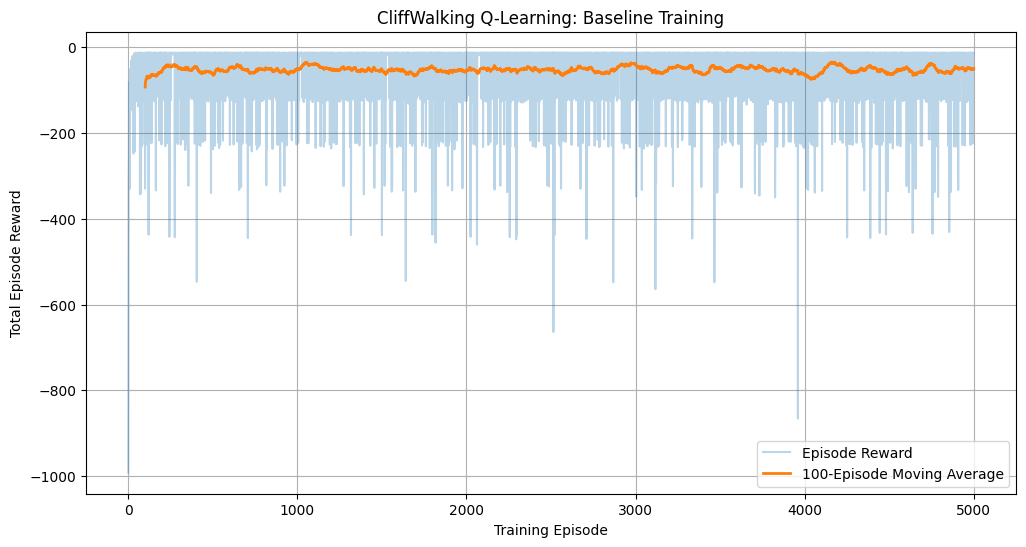

In [58]:
# Part C: Baseline Training Comparison Plot

import os

os.makedirs("results", exist_ok=True)

plt.figure(figsize=(12, 6))

window = 100

# Calculate moving average
moving_average = np.convolve(
    rewards_baseline,
    np.ones(window) / window,
    mode="valid"
)

# Plot individual episode rewards
plt.plot(
    rewards_baseline,
    alpha=0.3,
    label="Episode Reward"
)

# Plot moving average
plt.plot(
    np.arange(window, len(rewards_baseline) + 1),
    moving_average,
    linewidth=2,
    label="100-Episode Moving Average"
)

plt.xlabel("Training Episode")
plt.ylabel("Total Episode Reward")
plt.title("CliffWalking Q-Learning: Baseline Training")

plt.legend()
plt.grid(True)

plt.savefig(
    "results/baseline_reward.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Part D: Learning Rate Experiment

In [59]:
# Part D: Learning Rate Experiment

# Learning rates to test
learning_rates = [0.1, 0.5, 0.9]

# Store results
alpha_results = {}

for alpha in learning_rates:

  # Use same random seed for each experiment
  np.random.seed(42)

  # Train the agent
  Q_alpha, rewards_alpha = train_q_learning(
      alpha = alpha,
      gamma = 0.9,
      epsilon = 0.1,
      episodes = 5000
  )

  # Store Q-Table and rewars
  alpha_results[alpha] = {
      "Q": Q_alpha,
      "rewards": rewards_alpha
  }
  # Print results
  print(f"\nLearning Rate: {alpha}")
  print("Average reward (first 100 episodes):",
        np.mean(rewards_alpha[:100]))
  print("Average reward (last 100 episodes):",
        np.mean(rewards_alpha[-100:]))
  print("Best episode reward:", np.max(rewards_alpha))

print("\nLearning rate experiments competed!")


Learning Rate: 0.1
Average reward (first 100 episodes): -156.44
Average reward (last 100 episodes): -46.85
Best episode reward: -13

Learning Rate: 0.5
Average reward (first 100 episodes): -93.0
Average reward (last 100 episodes): -50.29
Best episode reward: -13

Learning Rate: 0.9
Average reward (first 100 episodes): -76.83
Average reward (last 100 episodes): -48.39
Best episode reward: -13

Learning rate experiments competed!


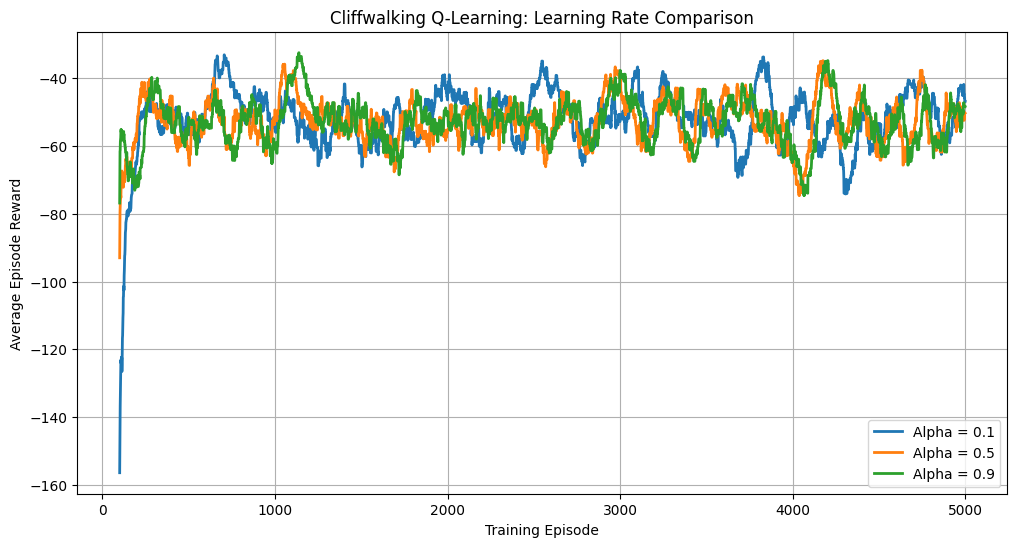

In [16]:
# Part D: Comparison Plot for Learning Rate

import os
os.makedirs("results", exist_ok=True)

plt.figure(figsize=(12, 6))
window = 100

for alpha in learning_rates:
  rewards = alpha_results[alpha]["rewards"]

 # Calculate moving avg
  moving_average = np.convolve(
     rewards,
     np.ones(window) / window,
     mode = "valid"
 )

# Plot moving average
  plt.plot(
      np.arange(window, len(rewards) + 1),
      moving_average,
      linewidth = 2,
      label = f"Alpha = {alpha}"
  )

plt.xlabel("Training Episode")
plt.ylabel("Average Episode Reward")
plt.title("Cliffwalking Q-Learning: Learning Rate Comparison")

plt.legend()
plt.grid(True)

# Save graph
plt.savefig(
    "results/learning_rate_comparison.png",
    dpi = 300,
    bbox_inches = "tight"
)

plt.show()

In [11]:
# Part D: Learning Rate Results Comparisons

print("=" * 65)
print("Learning Rate Experiment Results")
print("=" * 65)

print(f"{'Alpha':<10}{'First 100':<18}{'Last 100':<18}{'Best Reward'}")

for alpha in learning_rates:

  rewards = alpha_results[alpha]["rewards"]
  first_100 = np.mean(rewards[:100])
  last_100 = np.mean(rewards[-100:])
  best = np.max(rewards)

  print(f"{alpha:<10}{first_100:<18.2f}{last_100:<18.2f}{best:.2f}")


Learning Rate Experiment Results
Alpha     First 100         Last 100          Best Reward
0.1       -156.44           -46.85            -13.00
0.5       -93.00            -50.29            -13.00
0.9       -76.83            -48.39            -13.00


# Part E: Discount Factor Experiment

In [15]:
# Part E: Discount Factor Experiment

discount_factors = [0.5, 0.9, 0.99]

# Store results
gamma_results = {}

for gamma in discount_factors:

  # Set random seed
  np.random.seed(42)

  # Train the agent
  Q_gamma, rewards_gamma = train_q_learning(
      alpha = 0.5,
      gamma = gamma,
      epsilon = 0.1,
      episodes = 5000
  )

  # Store results
  gamma_results[gamma] = {
      "Q": Q_gamma,
      "rewards": rewards_gamma
  }

  # Print results
  print(f"\nDiscount Factor: {gamma}")

  print("Average reward (first 100 episodes):",
        np.mean(rewards_gamma[:100]))

  print("Average reward (last 100 episodes):",
        np.mean(rewards_gamma[-100:]))

  print("Best episode reward:",
        np.max(rewards_gamma))

print("\nDiscount factor experiments completed!")


Discount Factor: 0.5
Average reward (first 100 episodes): -92.63
Average reward (last 100 episodes): -47.19
Best episode reward: -13

Discount Factor: 0.9
Average reward (first 100 episodes): -93.0
Average reward (last 100 episodes): -50.29
Best episode reward: -13

Discount Factor: 0.99
Average reward (first 100 episodes): -83.21
Average reward (last 100 episodes): -50.29
Best episode reward: -13

Discount factor experiments completed!


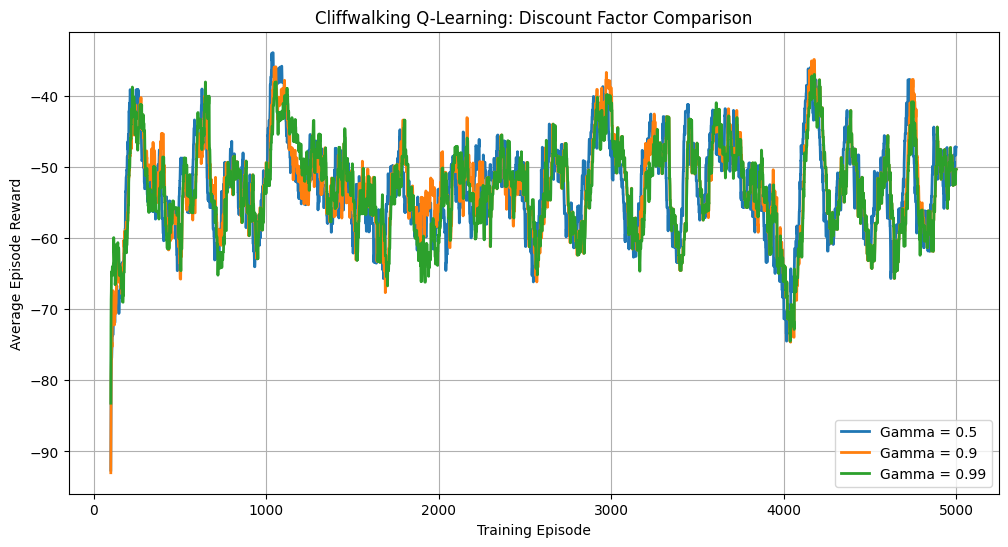

In [18]:
# Part E: Discount Factor Comparison Plot

plt.figure(figsize=(12, 6))
window = 100

for gamma in discount_factors:
  rewards = gamma_results[gamma]["rewards"]

  # Calculate moving average
  moving_average = np.convolve(
      rewards,
      np.ones(window) / window,
      mode = "valid"
  )

  # Plot moving average
  plt.plot(
      np.arange(window, len(rewards) + 1),
      moving_average,
      linewidth = 2,
      label = f"Gamma = {gamma}"
  )

  plt.xlabel("Training Episode")
  plt.ylabel("Average Episode Reward")
  plt.title("Cliffwalking Q-Learning: Discount Factor Comparison")

  plt.legend()
  plt.grid(True)

  # Save Graph
  plt.savefig(
      "results/discount_factor_comparison.png",
      dpi = 300,
      bbox_inches = "tight"
  )

plt.show()

# Part F: Exploration Rate Experiment

In [19]:
# Part F: Exploration Rate Experiment

exploration_rates = [0.05, 0.1, 0.3]

epsilon_results = {}

for epsilon in exploration_rates:

  # Set random seed
  np.random.seed(42)

  # Train agent
  Q_epsilon, rewards_epsilon = train_q_learning(
      alpha = 0.5,
      gamma = 0.9,
      epsilon = epsilon,
      episodes = 5000
  )

  # Store results
  epsilon_results[epsilon] = {
      "Q": Q_epsilon,
      "rewards": rewards_epsilon
  }

  # Print results
  print(f"\nExploration Rate: {epsilon}")

  print("Average reward (first 100 episodes):",
        np.mean(rewards_epsilon[:100]))
  print("Average reward (last 100 episodes):",
        np.mean(rewards_epsilon[-100:]))
  print("Best episode reward:",
        np.max(rewards_epsilon))

print("\nExploration rate experiments completed!")


Exploration Rate: 0.05
Average reward (first 100 episodes): -55.94
Average reward (last 100 episodes): -23.15
Best episode reward: -13

Exploration Rate: 0.1
Average reward (first 100 episodes): -93.0
Average reward (last 100 episodes): -50.29
Best episode reward: -13

Exploration Rate: 0.3
Average reward (first 100 episodes): -200.84
Average reward (last 100 episodes): -160.71
Best episode reward: -13

Exploration rate experiments completed!


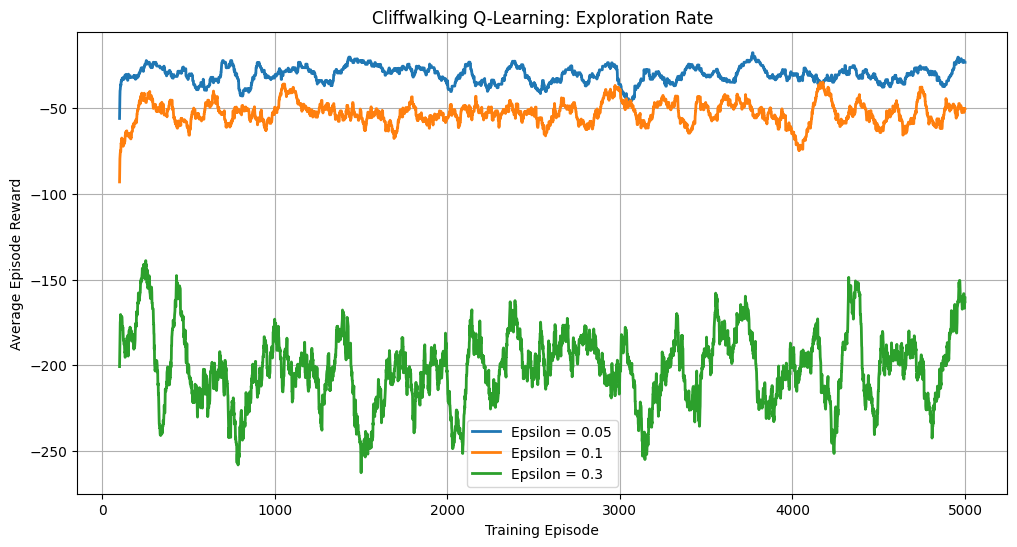

In [20]:
# Part F: Exploration Rate Comparison Plot

plt.figure(figsize=(12, 6))
window = 100

for epsilon in exploration_rates:
  rewards = epsilon_results[epsilon]["rewards"]

  # Calculate moving average
  moving_average = np.convolve(
      rewards,
      np.ones(window) / window,
      mode = "valid"
  )

  # Plot moving average
  plt.plot(
      np.arange(window, len(rewards) + 1),
      moving_average,
      linewidth = 2,
      label = f"Epsilon = {epsilon}"
  )

plt.xlabel("Training Episode")
plt.ylabel("Average Episode Reward")
plt.title("Cliffwalking Q-Learning: Exploration Rate")

plt.legend()
plt.grid(True)

#Save graph
plt.savefig(
    "results/exploration_rate_comparison.png",
    dpi = 300,
    bbox_inches = "tight"
)

plt.show()

In [21]:
# Part F: Exploration Rate Results Summary

print("=" * 65)
print("Exploration Rate Experiment Results")
print("=" * 65)

print(f"{'Epsilon':<10}{'First 100':<18}{'Last 100':<18}{'Best Reward'}")

for epsilon in exploration_rates:
  rewards = epsilon_results[epsilon]["rewards"]

  first_100 = np.mean(rewards[:100])
  last_100 = np.mean(rewards[-100:])
  best = np.max(rewards)

  print(
      f"{epsilon:<10}"
      f"{first_100:<18.2f}"
      f"{last_100:<18.2f}"
      f"{best:.2f}"
  )

Exploration Rate Experiment Results
Epsilon   First 100         Last 100          Best Reward
0.05      -55.94            -23.15            -13.00
0.1       -93.00            -50.29            -13.00
0.3       -200.84           -160.71           -13.00


# Part G: Best Agent Evaluation

In [36]:
# Part G: Evaluate Trained Agent

def evaluate_agent(Q, episodes = 100, max_steps = 200):

  # Create environment
  env = gym.make("CliffWalking-v1")

  episode_rewards = []
  episode_steps = []
  successes = 0
  total_cliff_falls = 0

  for episode in range(episodes):
    state, info = env.reset(seed = 42 + episode)
    total_reward = 0

    for step in range(max_steps):

      # Choose best action (no exploration)
      action = int(np.argmax(Q[state]))
      next_state, reward, terminated, truncated, info = env.step(action)

      total_reward += reward

      # Count cliff fails
      if reward == -100:
        total_cliff_falls += 1

      state = next_state

      # Check if goal was reached
      if terminated:
        successes += 1
        break

      if truncated:
        break

    episode_rewards.append(total_reward)
    episode_steps.append(step + 1)

  env.close()

  return {
      "mean_reward": np.mean(episode_rewards),
      "success_rate": successes / episodes * 100,
      "mean_steps": np.mean(episode_steps),
      "cliff_falls": total_cliff_falls
  }

In [39]:
# Part G: Compare Trained Agents

agents = {
    "Baseline": Q_baseline,
    "Alpha = 0.10": alpha_results[0.1]["Q"],
    "Alpha = 0.50": alpha_results[0.5]["Q"],
    "Alpha = 0.90": alpha_results[0.9]["Q"],

    "Gamma = 0.50": gamma_results[0.5]["Q"],
    "Gamma = 0.90": gamma_results[0.9]["Q"],
    "Gamma = 0.99": gamma_results[0.99]["Q"],

    "Epsilon = 0.05": epsilon_results[0.05]["Q"],
    "Epsilon = 0.10": epsilon_results[0.1]["Q"],
    "Epsilon = 0.30": epsilon_results[0.3]["Q"],
}

evaluation_results = {}

print("=" * 65)
print("Part G: Trained Agent Evaluation Results")
print("=" * 65)

for name, Q in agents.items():

  results = evaluate_agent(Q, episodes = 100)

  evaluation_results[name] = results

  print(f"\n{name}")
  print(f"Mean Reward: {results['mean_reward']:.2f}")
  print(f"Success Rate: {results['success_rate']:.2f}%")
  print(f"Mean Steps: {results['mean_steps']:.2f}")
  print(f"Cliff Falls: {results['cliff_falls']}")

#


Part G: Trained Agent Evaluation Results

Baseline
Mean Reward: -13.00
Success Rate: 100.00%
Mean Steps: 13.00
Cliff Falls: 0

Alpha = 0.10
Mean Reward: -13.00
Success Rate: 100.00%
Mean Steps: 13.00
Cliff Falls: 0

Alpha = 0.50
Mean Reward: -13.00
Success Rate: 100.00%
Mean Steps: 13.00
Cliff Falls: 0

Alpha = 0.90
Mean Reward: -13.00
Success Rate: 100.00%
Mean Steps: 13.00
Cliff Falls: 0

Gamma = 0.50
Mean Reward: -13.00
Success Rate: 100.00%
Mean Steps: 13.00
Cliff Falls: 0

Gamma = 0.90
Mean Reward: -13.00
Success Rate: 100.00%
Mean Steps: 13.00
Cliff Falls: 0

Gamma = 0.99
Mean Reward: -13.00
Success Rate: 100.00%
Mean Steps: 13.00
Cliff Falls: 0

Epsilon = 0.05
Mean Reward: -13.00
Success Rate: 100.00%
Mean Steps: 13.00
Cliff Falls: 0

Epsilon = 0.10
Mean Reward: -13.00
Success Rate: 100.00%
Mean Steps: 13.00
Cliff Falls: 0

Epsilon = 0.30
Mean Reward: -13.00
Success Rate: 100.00%
Mean Steps: 13.00
Cliff Falls: 0


In [40]:
# Part G: Identify Best Agent

best_agent_name = max(
    evaluation_results,
    key = lambda name:(
        evaluation_results[name]["success_rate"],
        evaluation_results[name]["mean_reward"],
        -evaluation_results[name]["mean_steps"]
    )
  )

best_results = evaluation_results[best_agent_name]
baseline_results = evaluation_results["Baseline"]

best_Q = agents[best_agent_name]

print("=" * 65)
print("Part G: Best Agent Results")
print("=" * 65)

print("Best Configuration:", best_agent_name)

print("\nBaseline Agent")
print(f"Mean Reward: {baseline_results['mean_reward']:.2f}")
print(f"Success Rate: {baseline_results['success_rate']:.1f}%")
print(f"Mean Steps: {baseline_results['mean_steps']:.2f}")
print(f"Cliff Falls: {baseline_results['cliff_falls']}")

print("\nBest Agent")
print(f"Mean Reward: {best_results['mean_reward']:.2f}")
print(f"Success Rate: {best_results['success_rate']:.1f}%")
print(f"Mean Steps: {best_results['mean_steps']:.2f}")
print(f"Cliff Falls: {best_results['cliff_falls']}")


Part G: Best Agent Results
Best Configuration: Baseline

Baseline Agent
Mean Reward: -13.00
Success Rate: 100.0%
Mean Steps: 13.00
Cliff Falls: 0

Best Agent
Mean Reward: -13.00
Success Rate: 100.0%
Mean Steps: 13.00
Cliff Falls: 0


#Trained Agent Video

In [43]:
import gymnasium as gym
import numpy as np
import imageio
import os

from IPython.display import Video, display

# Create results folder
os.makedirs("results", exist_ok=True)

# Create environment with rendering enabled
env = gym.make("CliffWalking-v1", render_mode = "rgb_array")

# Reset Environment
state, info = env.reset(seed = 42)

# Store video frames
frames = []

# Capture starting frame
frames.append(env.render())

total_reward = 0
steps = 0
success = False

# Run trained agent without exploration
for step in range(200):
  # Select best action
    action = int(np.argmax(best_Q[state]))

    # Take action
    next_state, reward, terminated, truncated, info = env.step(action)

    total_reward += reward
    steps += 1

    # Capture frame
    frames.append(env.render())

    state = next_state

    if terminated:
        success = True
        break

    if truncated:
        break

env.close()

# Save video
video_path = "results/best_agent.mp4"

imageio.mimsave(
    video_path,
    frames,
    fps=2
)

print("Video saved successfully!")
print("File:", video_path)
print("Total Reward:", total_reward)
print("Steps:", steps)
print("Reached Goal:", success)

# Display video
display(Video(video_path, embed=True))

Video saved successfully!
File: results/best_agent.mp4
Total Reward: -13
Steps: 13
Reached Goal: True


# Part H: Stochastic Environment

In [54]:
# Part H: Stochastic Q-Learning

def noisy_action(action, noise_probability, rng, n_actions=4):

    # With probability p, execute a different valid action
    if rng.random() < noise_probability:

        # Select one of the other three actions
        change = rng.integers(1, n_actions)

        return int((action + change) % n_actions)

    # Otherwise, execute the intended action
    return action


def train_stochastic_q_learning(
    alpha=0.5,
    gamma=0.9,
    epsilon=0.1,
    episodes=5000,
    max_steps=200,
    noise_probability=0.0,
    seed=42
):

    env = gym.make("CliffWalking-v1")

    # Initialize Q-table
    Q = np.zeros((env.observation_space.n, env.action_space.n))

    episode_rewards = []

    # Set random seeds
    np.random.seed(seed)
    noise_rng = np.random.default_rng(seed)

    for episode in range(episodes):

        state, info = env.reset(seed=seed + episode)

        total_reward = 0

        for step in range(max_steps):

            # Select intended action using epsilon-greedy
            action = choose_action(Q, state, epsilon)

            # Introduce action noise
            actual_action = noisy_action(
                action,
                noise_probability,
                noise_rng,
                env.action_space.n
            )

            # Execute actual action
            next_state, reward, terminated, truncated, info = env.step(
                actual_action
            )

            # Calculate Q-learning target
            if terminated:
                target = reward
            else:
                target = reward + gamma * np.max(Q[next_state])

            # Update Q-value for the intended action
            Q[state, action] += alpha * (
                target - Q[state, action]
            )

            total_reward += reward
            state = next_state

            if terminated or truncated:
                break

        episode_rewards.append(total_reward)

    env.close()

    return Q, episode_rewards

In [55]:
# Part H: Train Agents with Different Noise Levels

noise_levels = [0.0, 0.10, 0.25]

stochastic_results = {}

for p in noise_levels:

    Q_noisy, rewards_noisy = train_stochastic_q_learning(
        alpha=0.5,
        gamma=0.9,
        epsilon=0.1,
        episodes=5000,
        max_steps=200,
        noise_probability=p,
        seed=42
    )

    stochastic_results[p] = {
        "Q": Q_noisy,
        "rewards": rewards_noisy
    }

    print(f"\nAction Noise: {p}")

    print(
        "Average reward (first 100 episodes):",
        np.mean(rewards_noisy[:100])
    )

    print(
        "Average reward (last 100 episodes):",
        np.mean(rewards_noisy[-100:])
    )

    print(
        "Best episode reward:",
        np.max(rewards_noisy)
    )

print("\nStochastic training completed!")


Action Noise: 0.0
Average reward (first 100 episodes): -93.0
Average reward (last 100 episodes): -50.29
Best episode reward: -13

Action Noise: 0.1
Average reward (first 100 episodes): -121.73
Average reward (last 100 episodes): -49.7
Best episode reward: -17

Action Noise: 0.25
Average reward (first 100 episodes): -299.38
Average reward (last 100 episodes): -323.86
Best episode reward: -17

Stochastic training completed!


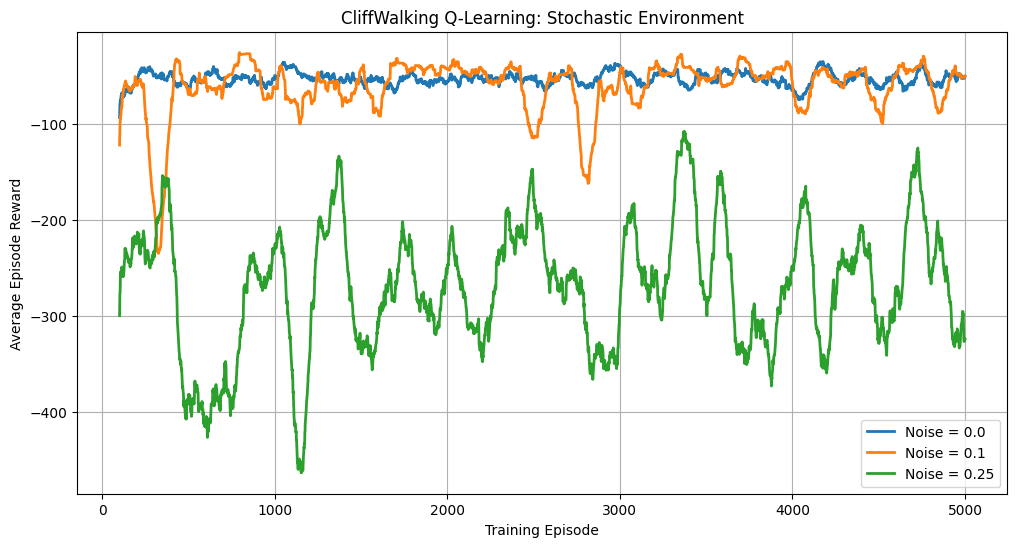

In [49]:
# Part H: Stochastic Training Comparison Plot

plt.figure(figsize=(12, 6))

window = 100

for p in noise_levels:

    rewards = stochastic_results[p]["rewards"]

    # Calculate moving average
    moving_average = np.convolve(
        rewards,
        np.ones(window) / window,
        mode="valid"
    )

    # Plot moving average
    plt.plot(
        np.arange(window, len(rewards) + 1),
        moving_average,
        linewidth=2,
        label=f"Noise = {p}"
    )

# Everything below is OUTSIDE the loop

plt.xlabel("Training Episode")

plt.ylabel("Average Episode Reward")

plt.title("CliffWalking Q-Learning: Stochastic Environment")

plt.legend()

plt.grid(True)

plt.savefig(
    "results/stochastic_training_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [50]:
# Part H: Stochastic Agent Evaluation Function

def evaluate_stochastic_agent(
    Q,
    noise_probability=0.0,
    episodes=200,
    max_steps=200,
    seed=123
):

    env = gym.make("CliffWalking-v1")

    episode_rewards = []
    episode_steps = []

    successes = 0
    total_cliff_falls = 0

    for episode in range(episodes):

        state, info = env.reset(seed=seed + episode)

        # Separate random generator for each episode
        rng = np.random.default_rng(seed + episode)

        total_reward = 0

        for step in range(max_steps):

            # Greedy policy: no epsilon exploration
            action = int(np.argmax(Q[state]))

            # Apply environmental noise
            actual_action = noisy_action(
                action,
                noise_probability,
                rng,
                env.action_space.n
            )

            next_state, reward, terminated, truncated, info = env.step(
                actual_action
            )

            total_reward += reward

            if reward == -100:
                total_cliff_falls += 1

            state = next_state

            if terminated:
                successes += 1
                break

            if truncated:
                break

        episode_rewards.append(total_reward)
        episode_steps.append(step + 1)

    env.close()

    return {
        "mean_reward": np.mean(episode_rewards),
        "success_rate": successes / episodes * 100,
        "mean_steps": np.mean(episode_steps),
        "cliff_falls": total_cliff_falls,
        "falls_per_episode": total_cliff_falls / episodes
    }

In [52]:
# Part H: Evaluate Noise-Trained and Original Agents

stochastic_evaluation = {}
baseline_robustness = {}

print("=" * 75)
print("Part H: Stochastic Environment Evaluation")
print("=" * 75)

for p in noise_levels:

    # Evaluate agent trained under this noise level
    trained_Q = stochastic_results[p]["Q"]

    trained_eval = evaluate_stochastic_agent(
        trained_Q,
        noise_probability=p,
        episodes=200
    )

    stochastic_evaluation[p] = trained_eval

    # Evaluate original baseline agent under same noise
    baseline_eval = evaluate_stochastic_agent(
        Q_baseline,
        noise_probability=p,
        episodes=200
    )

    baseline_robustness[p] = baseline_eval

    print(f"\nNoise Probability: {p}")

    print("\nAgent Trained Under Noise:")
    print(f"Mean Reward: {trained_eval['mean_reward']:.2f}")
    print(f"Success Rate: {trained_eval['success_rate']:.1f}%")
    print(f"Mean Steps: {trained_eval['mean_steps']:.2f}")
    print(f"Cliff Falls: {trained_eval['cliff_falls']}")

    print("\nOriginal Baseline Agent:")
    print(f"Mean Reward: {baseline_eval['mean_reward']:.2f}")
    print(f"Success Rate: {baseline_eval['success_rate']:.1f}%")
    print(f"Mean Steps: {baseline_eval['mean_steps']:.2f}")
    print(f"Cliff Falls: {baseline_eval['cliff_falls']}")

print("\nStochastic evaluation completed!")

Part H: Stochastic Environment Evaluation

Noise Probability: 0.0

Agent Trained Under Noise:
Mean Reward: -13.00
Success Rate: 100.0%
Mean Steps: 13.00
Cliff Falls: 0

Original Baseline Agent:
Mean Reward: -13.00
Success Rate: 100.0%
Mean Steps: 13.00
Cliff Falls: 0

Noise Probability: 0.1

Agent Trained Under Noise:
Mean Reward: -25.63
Success Rate: 100.0%
Mean Steps: 21.18
Cliff Falls: 9

Original Baseline Agent:
Mean Reward: -63.28
Success Rate: 100.0%
Mean Steps: 18.23
Cliff Falls: 91

Noise Probability: 0.25

Agent Trained Under Noise:
Mean Reward: -259.62
Success Rate: 14.0%
Mean Steps: 187.35
Cliff Falls: 146

Original Baseline Agent:
Mean Reward: -171.51
Success Rate: 100.0%
Mean Steps: 30.93
Cliff Falls: 284

Stochastic evaluation completed!


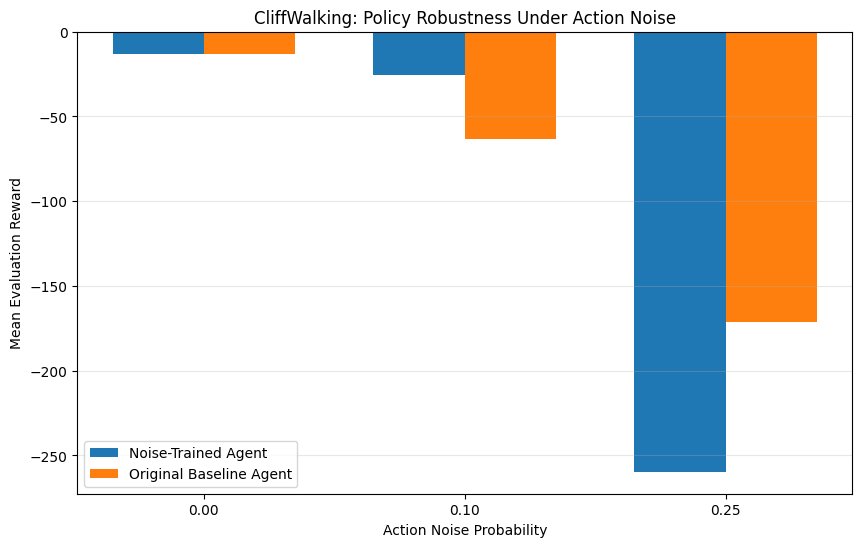

In [53]:
# Part H: Policy Robustness Comparison Plot

noise_labels = ["0.00", "0.10", "0.25"]

trained_rewards = [
    stochastic_evaluation[p]["mean_reward"]
    for p in noise_levels
]

baseline_rewards = [
    baseline_robustness[p]["mean_reward"]
    for p in noise_levels
]

x = np.arange(len(noise_levels))

width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    trained_rewards,
    width,
    label="Noise-Trained Agent"
)

plt.bar(
    x + width / 2,
    baseline_rewards,
    width,
    label="Original Baseline Agent"
)

plt.xlabel("Action Noise Probability")

plt.ylabel("Mean Evaluation Reward")

plt.title("CliffWalking: Policy Robustness Under Action Noise")

plt.xticks(x, noise_labels)

plt.legend()

plt.grid(axis="y", alpha=0.3)

plt.savefig(
    "results/stochastic_robustness_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [57]:
# Save all results in a ZIP file

import shutil
from google.colab import files

# Create ZIP containing results folder
shutil.make_archive(
    "/content/CPSC4420_Assignment2_Results",
    "zip",
    "results"
)

# Download ZIP
files.download(
    "/content/CPSC4420_Assignment2_Results.zip"
)

print("Results downloaded successfully!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Results downloaded successfully!
